# Tarea 4 — Inteligencia Artificial

**Dataset:** *Fruits Classification* (Kaggle). 10.000 imágenes JPEG/PNG, 5 clases balanceadas (Apple, Banana, Grape, Mango, Strawberry), redimensionadas a 64×64.

**Entrega:** notebook ejecutable de principio a fin, semilla fija, separación train/val/test compartida por todos los modelos y pesos finales guardados con `torch.save(modelo.state_dict(), ...)`.

**Contenido**
1. Convolución a mano y verificación en PyTorch.
2. Datos y MLP.
3. CNN, experimentos de arquitectura y regularización.
4. Análisis: matriz de confusión, filtros y comparación MLP vs CNN.

El conjunto de prueba se evalúa **una sola vez**, al final de la sección 4.

## 0. Configuración, semilla y dispositivo

In [1]:
import random
from pathlib import Path

import numpy as np
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision.transforms import Compose, Resize, ToTensor, InterpolationMode
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

SEED = 42
CLASS_NAMES = ["Apple", "Banana", "Grape", "Mango", "Strawberry"]
DATA_DIR = Path("Fruits Classification")
IMG_SIZE = 64


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed()
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("torch:", torch.__version__, "| dispositivo:", device)

torch: 2.15.0 | dispositivo: mps


## 1. Convolución a mano (4 puntos)

Datos de la consigna: imagen $X$ de 5×5 y filtro $K$ de 3×3.

$$
X=\begin{pmatrix}
1&0&2&1&0\\
0&1&3&1&1\\
2&1&0&0&2\\
1&0&1&2&1\\
0&2&1&1&0
\end{pmatrix},
\qquad
K=\begin{pmatrix}
1&0&-1\\
1&0&-1\\
1&0&-1
\end{pmatrix}
$$

La salida de la convolución (stride 1, sin padding, sin sesgo) es

$$
y_{ij}=\sum_{u=1}^{3}\sum_{v=1}^{3} x_{i+u-1,\,j+v-1}\,K_{uv},
$$

y como el filtro cabe en $5-3+1=3$ posiciones por dirección, la salida es de 3×3.

**Celda desarrollada a mano**, esquina superior izquierda ($i=1,j=1$):

$$
\begin{aligned}
y_{11}&=(1\cdot1+0\cdot0+2\cdot(-1))\\
     &+(0\cdot1+1\cdot0+3\cdot(-1))\\
     &+(2\cdot1+1\cdot0+0\cdot(-1))\\
     &=(-1)+(-3)+2=-2.
\end{aligned}
$$

Las demás celdas se calculan igual, desplazando la ventana. Después se aplica ReLU, $\max(z,0)$, y un max pooling de 2×2 con stride 1, que toma el máximo de cada bloque y produce 2×2.

**Pregunta final del punto:** `nn.Conv2d(3, 16, kernel_size=3)` tiene $(3\cdot3\cdot3+1)\cdot16=448$ parámetros. Una capa densa que recibe $32\cdot32\cdot3=3072$ entradas y produce $30\cdot30\cdot16=14400$ salidas tiene $(3072+1)\cdot14400=44\,251\,200$ parámetros.

### 1.1 Cálculo a mano con `for` anidados

Esta función no usa PyTorch: hace exactamente las sumas de la fórmula, por lo que sirve para cualquier imagen y filtro (no solo los de la consigna).

In [2]:
X = [
    [1, 0, 2, 1, 0],
    [0, 1, 3, 1, 1],
    [2, 1, 0, 0, 2],
    [1, 0, 1, 2, 1],
    [0, 2, 1, 1, 0],
]
K = [
    [1, 0, -1],
    [1, 0, -1],
    [1, 0, -1],
]


def conv2d_manual(image, kernel, stride=1):
    n, m = len(image), len(image[0])
    k = len(kernel)
    result = []
    for i in range(0, n - k + 1, stride):
        row = []
        for j in range(0, m - k + 1, stride):
            value = 0
            for u in range(k):
                for v in range(k):
                    value += image[i + u][j + v] * kernel[u][v]
            row.append(value)
        result.append(row)
    return result


def relu_manual(matrix):
    return [[max(0, z) for z in row] for row in matrix]


def maxpool2d_manual(matrix, k=2, stride=1):
    n, m = len(matrix), len(matrix[0])
    result = []
    for i in range(0, n - k + 1, stride):
        row = []
        for j in range(0, m - k + 1, stride):
            window = [matrix[i + u][j + v] for u in range(k) for v in range(k)]
            row.append(max(window))
        result.append(row)
    return result


def print_matrix(name, matrix):
    print(name)
    for row in matrix:
        print("  ", row)


conv_manual = conv2d_manual(X, K)
relu_manual = relu_manual(conv_manual)
pool_manual = maxpool2d_manual(relu_manual)
print_matrix("Convolución (3x3):", conv_manual)
print_matrix("Tras ReLU (3x3):", relu_manual)
print_matrix("Tras max pooling (2x2):", pool_manual)

Convolución (3x3):
   [-2, 0, 2]
   [-1, -1, 0]
   [1, 0, -1]
Tras ReLU (3x3):
   [0, 0, 2]
   [0, 0, 0]
   [1, 0, 0]
Tras max pooling (2x2):
   [0, 2]
   [1, 0]


### 1.2 Verificación con PyTorch

Dentro de una CNN, `nn.Conv2d` calcula correlación cruzada (no voltea el filtro), que es justamente la operación que hicimos a mano. Asignamos los pesos con `with torch.no_grad()` y comparamos con `torch.allclose`. El tensor de entrada tiene forma `(N, C, H, W) = (1, 1, 5, 5)`.

In [3]:
Xt = torch.tensor(X, dtype=torch.float32).reshape(1, 1, 5, 5)
Kt = torch.tensor(K, dtype=torch.float32)

conv = nn.Conv2d(1, 1, kernel_size=3, stride=1, padding=0, bias=False)
with torch.no_grad():
    conv.weight[0, 0] = Kt

out_conv = conv(Xt)
out_relu = torch.relu(out_conv)
out_pool = nn.MaxPool2d(kernel_size=2, stride=1)(out_relu)

print("forma convolución:", tuple(out_conv.shape))
print("forma pooling:", tuple(out_pool.shape))
print("convolución:\n", out_conv[0, 0])
print("tras ReLU:\n", out_relu[0, 0])
print("tras pooling:\n", out_pool[0, 0])

assert torch.allclose(out_conv[0, 0], torch.tensor(conv_manual, dtype=torch.float32))
assert torch.allclose(out_relu[0, 0], torch.tensor(relu_manual, dtype=torch.float32))
assert torch.allclose(out_pool[0, 0], torch.tensor(pool_manual, dtype=torch.float32))
print("Verificación OK: PyTorch coincide con el cálculo a mano.")

forma convolución: (1, 1, 3, 3)
forma pooling: (1, 1, 2, 2)
convolución:
 tensor([[-2.,  0.,  2.],
        [-1., -1.,  0.],
        [ 1.,  0., -1.]], grad_fn=<SelectBackward0>)
tras ReLU:
 tensor([[0., 0., 2.],
        [0., 0., 0.],
        [1., 0., 0.]], grad_fn=<SelectBackward0>)
tras pooling:
 tensor([[0., 2.],
        [1., 0.]], grad_fn=<SelectBackward0>)
Verificación OK: PyTorch coincide con el cálculo a mano.


In [4]:
params_conv = (3 * 3 * 3 + 1) * 16
params_densa = (32 * 32 * 3 + 1) * (30 * 30 * 16)
print("Conv2d(3, 16, kernel_size=3):", params_conv, "parámetros")
print("Densa 3072 -> 14400:", params_densa, "parámetros")

Conv2d(3, 16, kernel_size=3): 448 parámetros
Densa 3072 -> 14400: 44251200 parámetros


## 2. Datos y MLP

Cargamos las 10.000 imágenes una sola vez, aplicamos **resize directo a 64×64** con interpolación bilineal (sin crop ni padding, según lo acordado) y guardamos el resultado como `uint8`. Luego hacemos una separación **estratificada 70/15/15** con semilla 42. El split original del dataset es 97/2/1 (solo 100 imágenes de test), demasiado chico para curvas y matriz de confusión estables.

Todos los modelos de la tarea usan estos mismos índices.

In [5]:
paths, labels = [], []
for split in ["train", "valid", "test"]:
    for class_idx, name in enumerate(CLASS_NAMES):
        folder = DATA_DIR / split / name
        for path in folder.iterdir():
            if path.suffix.lower() in {".jpeg", ".jpg", ".png"}:
                paths.append(path)
                labels.append(class_idx)

transform = Compose([
    Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BILINEAR),
    ToTensor(),
])

X_all = torch.empty((len(paths), 3, IMG_SIZE, IMG_SIZE), dtype=torch.uint8)
y_all = torch.tensor(labels, dtype=torch.long)

for idx, path in enumerate(paths):
    with Image.open(path) as image:
        tensor = transform(image.convert("RGB"))
    X_all[idx] = (tensor * 255).round().to(torch.uint8)
    if (idx + 1) % 2500 == 0:
        print(f"redimensionadas {idx + 1}/{len(paths)}")

X_float = X_all.float().div_(255.0)
print("X_all:", tuple(X_all.shape), "| y_all:", tuple(y_all.shape))

redimensionadas 2500/10000


redimensionadas 5000/10000


redimensionadas 7500/10000


redimensionadas 10000/10000
X_all: (10000, 3, 64, 64) | y_all: (10000,)


In [6]:
indices = np.arange(len(y_all))
idx_train, idx_temp, _, _ = train_test_split(
    indices, y_all.numpy(), test_size=0.30, stratify=y_all.numpy(), random_state=SEED
)
idx_val, idx_test, _, _ = train_test_split(
    idx_temp, y_all.numpy()[idx_temp], test_size=0.50,
    stratify=y_all.numpy()[idx_temp], random_state=SEED
)
idx_train = torch.from_numpy(idx_train)
idx_val = torch.from_numpy(idx_val)
idx_test = torch.from_numpy(idx_test)

y_train = y_all[idx_train]
y_val = y_all[idx_val]
y_test = y_all[idx_test]

print("tamaños -> train:", len(idx_train), "| val:", len(idx_val), "| test:", len(idx_test))
print("proporción de ejemplos por clase en cada conjunto:")
for split_name, y_split in zip(["train", "val", "test"], [y_train, y_val, y_test]):
    counts = np.bincount(y_split.numpy(), minlength=5)
    proportions = [round(float(value), 3) for value in counts / len(y_split)]
    print(f"  {split_name:6s}", dict(zip(CLASS_NAMES, proportions)))

tamaños -> train: 7000 | val: 1500 | test: 1500
proporción de ejemplos por clase en cada conjunto:
  train  {'Apple': 0.2, 'Banana': 0.2, 'Grape': 0.2, 'Mango': 0.2, 'Strawberry': 0.2}
  val    {'Apple': 0.2, 'Banana': 0.2, 'Grape': 0.2, 'Mango': 0.2, 'Strawberry': 0.2}
  test   {'Apple': 0.2, 'Banana': 0.2, 'Grape': 0.2, 'Mango': 0.2, 'Strawberry': 0.2}


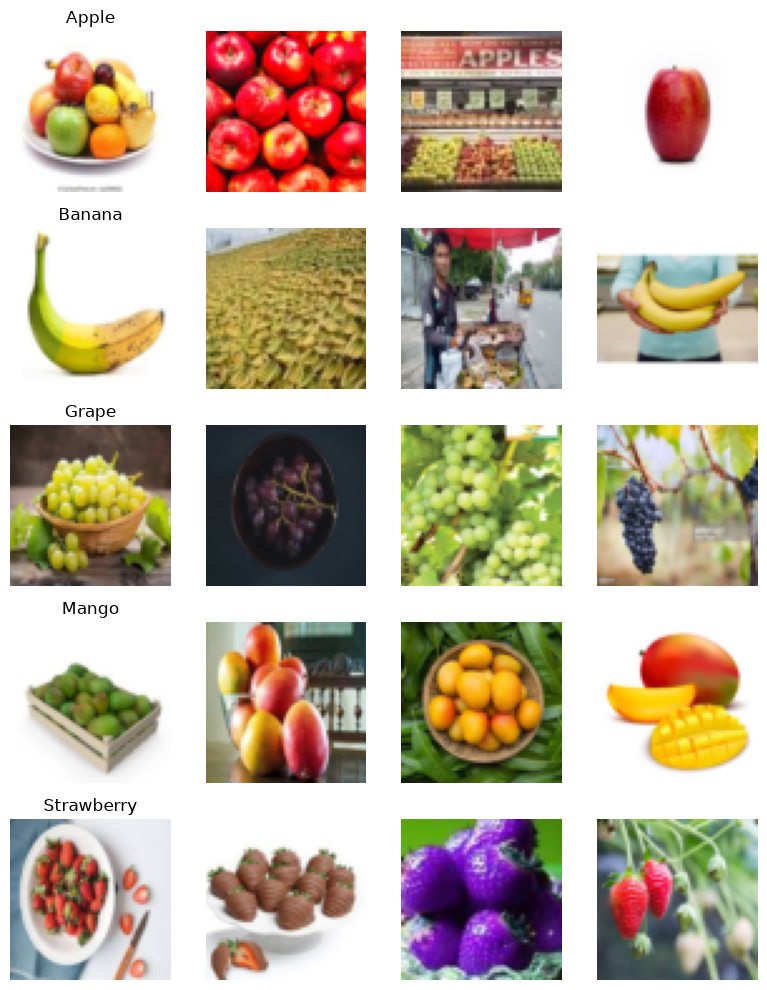

In [7]:
fig, axes = plt.subplots(5, 4, figsize=(8, 10))
for row, name in enumerate(CLASS_NAMES):
    examples = torch.where(y_train == row)[0][:4]
    for col, idx in enumerate(examples):
        axes[row, col].imshow(X_all[idx_train[idx]].permute(1, 2, 0).numpy())
        axes[row, col].set_title(name if col == 0 else "")
        axes[row, col].axis("off")
plt.tight_layout()
plt.show()

### 2.1 MLP

La imagen se aplana a $3\cdot64\cdot64=12288$ entradas. La red es `12288 → 256 → 128 → 5` con ReLU en las capas ocultas. La última capa devuelve **logits** (sin softmax), porque `nn.CrossEntropyLoss` aplica internamente log-softmax.

In [8]:
class MLP(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(3 * IMG_SIZE * IMG_SIZE, 256)
        self.fc2 = nn.Linear(256, 128)
        self.out = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.flatten(x)
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        return self.out(x)


mlp = MLP().to(device)
print("parámetros MLP:", sum(p.numel() for p in mlp.parameters()))

parámetros MLP: 3179525


### 2.2 Ciclo de entrenamiento

Un **mini-batch** son 128 ejemplos, un **paso** es una actualización de parámetros (forward, pérdida, backward, step) y una **época** es una pasada completa por los 7000 ejemplos de entrenamiento: $\lceil 7000/128\rceil=55$ pasos por época.

`optimizer.zero_grad()` es indispensable: `loss.backward()` **acumula** gradientes en `.grad`, así que sin borrarlos se usaría la suma de todos los pasos anteriores y el entrenamiento fallaría sin lanzar error. No se aplica softmax antes de `CrossEntropyLoss` porque la propia pérdida lo incluye y es más estable numéricamente.

El mejor estado se guarda por época según la pérdida de validación (*early stopping*).

In [9]:
def make_loaders(batch_size=128, seed=SEED):
    generator = torch.Generator().manual_seed(seed)
    train_loader = DataLoader(
        TensorDataset(X_float[idx_train], y_train),
        batch_size=batch_size, shuffle=True, generator=generator,
    )
    val_loader = DataLoader(
        TensorDataset(X_float[idx_val], y_val), batch_size=batch_size, shuffle=False
    )
    test_loader = DataLoader(
        TensorDataset(X_float[idx_test], y_test), batch_size=batch_size, shuffle=False
    )
    return train_loader, val_loader, test_loader


def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            batch_size = yb.size(0)
            total_loss += criterion(logits, yb).item() * batch_size
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += batch_size
    return total_loss / total, correct / total


def train_model(model, train_loader, val_loader, epochs=12, lr=1e-3,
                weight_decay=0.0, early_stop=True):
    model = model.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_loss, best_state, best_epoch = float("inf"), None, 0

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            batch_size = yb.size(0)
            total_loss += loss.item() * batch_size
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += batch_size

        train_loss, train_acc = total_loss / total, correct / total
        val_loss, val_acc = evaluate(model, val_loader, criterion)
        for key, value in zip(history, [train_loss, train_acc, val_loss, val_acc]):
            history[key].append(value)

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            best_epoch = epoch
        if epoch == 1 or epoch % 5 == 0:
            print(f"época {epoch:2d} | train {train_loss:.3f}/{train_acc:.3f} | val {val_loss:.3f}/{val_acc:.3f}")

    if early_stop:
        model.load_state_dict(best_state)
    history["best_epoch"] = best_epoch
    return model, history

In [10]:
set_seed()
train_loader, val_loader, test_loader = make_loaders()
mlp, history_mlp = train_model(mlp, train_loader, val_loader, epochs=15)
print("mejor época MLP:", history_mlp["best_epoch"])
print("exactitud de validación MLP:", round(max(history_mlp["val_acc"]), 4))

época  1 | train 1.610/0.293 | val 1.424/0.356


época  5 | train 1.252/0.468 | val 1.232/0.464


época 10 | train 1.178/0.499 | val 1.281/0.447


época 15 | train 1.133/0.525 | val 1.217/0.472
mejor época MLP: 12
exactitud de validación MLP: 0.4987


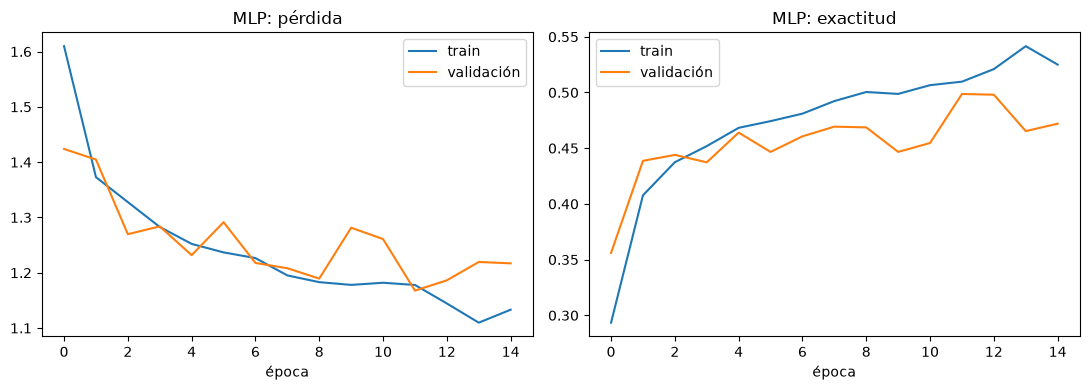

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history_mlp["train_loss"], label="train")
axes[0].plot(history_mlp["val_loss"], label="validación")
axes[0].set_title("MLP: pérdida")
axes[0].set_xlabel("época")
axes[0].legend()
axes[1].plot(history_mlp["train_acc"], label="train")
axes[1].plot(history_mlp["val_acc"], label="validación")
axes[1].set_title("MLP: exactitud")
axes[1].set_xlabel("época")
axes[1].legend()
plt.tight_layout()
plt.show()

## 3. CNN y arquitectura

Arquitectura base: dos bloques de `Conv2d → ReLU → MaxPool2d(2)`, seguidos de aplanado y una capa densa de salida. Con padding 1 y kernel 3 las convoluciones conservan el tamaño; cada pooling lo divide por 2:

| capa | forma de salida (sin batch) | parámetros |
|---|---|---|
| entrada | 3 × 64 × 64 | 0 |
| conv1: Conv2d(3, 8, 3, padding=1) + ReLU | 8 × 64 × 64 | $(3\cdot9+1)\cdot8=224$ |
| pool1: MaxPool2d(2) | 8 × 32 × 32 | 0 |
| conv2: Conv2d(8, 16, 3, padding=1) + ReLU | 16 × 32 × 32 | $(8\cdot9+1)\cdot16=1168$ |
| pool2: MaxPool2d(2) | 16 × 16 × 16 | 0 |
| aplanar | 4096 | 0 |
| densa: Linear(4096, 5) | 5 | $4096\cdot5+5=20485$ |
| **total** | | **21877** |

La primera capa densa tiene 4096 entradas porque $64\to32\to16$ y hay 16 canales: $16\cdot16\cdot16$. Verificamos las formas con un forward de prueba y los parámetros con `p.numel()`.

In [12]:
class CNN(nn.Module):
    def __init__(self, channels=(8, 16), kernel_size=3, hidden=(), dropout=0.0, num_classes=5):
        super().__init__()
        self.conv_blocks = nn.ModuleList()
        in_channels = 3
        for out_channels in channels:
            self.conv_blocks.append(nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size, padding=kernel_size // 2),
                nn.ReLU(),
                nn.MaxPool2d(2),
            ))
            in_channels = out_channels

        self.flatten = nn.Flatten()
        spatial = IMG_SIZE // (2 ** len(channels))
        flat_dim = channels[-1] * spatial * spatial
        layers = []
        for units in hidden:
            layers += [nn.Linear(flat_dim, units), nn.ReLU()]
            if dropout > 0:
                layers.append(nn.Dropout(dropout))
            flat_dim = units
        self.classifier_head = nn.Sequential(*layers) if layers else nn.Identity()
        self.dropout = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        self.out = nn.Linear(flat_dim, num_classes)

    def forward(self, x):
        for block in self.conv_blocks:
            x = block(x)
        x = self.flatten(x)
        x = self.classifier_head(x)
        x = self.dropout(x)
        return self.out(x)


def layer_table(model, example):
    rows = []
    handles = []

    def make_hook(name):
        def hook(module, inputs, output):
            params = sum(p.numel() for p in module.parameters())
            rows.append((name, tuple(output.shape), params))
        return hook

    for name, module in model.named_modules():
        if name and not isinstance(module, (nn.Sequential, nn.ModuleList)):
            handles.append(module.register_forward_hook(make_hook(name)))
    with torch.no_grad():
        model(example)
    for handle in handles:
        handle.remove()
    return rows


base_cnn = CNN()
print("parámetros CNN base:", sum(p.numel() for p in base_cnn.parameters()))
rows = layer_table(base_cnn, torch.randn(1, 3, IMG_SIZE, IMG_SIZE))
print(f"{'capa':20s} {'forma de salida':20s} {'parámetros':>10s}")
for name, shape, params in rows:
    print(f"{name:20s} {str(shape):20s} {params:10d}")
print("suma por capa:", sum(r[2] for r in rows))

parámetros CNN base: 21877
capa                 forma de salida      parámetros
conv_blocks.0.0      (1, 8, 64, 64)              224
conv_blocks.0.1      (1, 8, 64, 64)                0
conv_blocks.0.2      (1, 8, 32, 32)                0
conv_blocks.1.0      (1, 16, 32, 32)            1168
conv_blocks.1.1      (1, 16, 32, 32)               0
conv_blocks.1.2      (1, 16, 16, 16)               0
flatten              (1, 4096)                     0
classifier_head      (1, 4096)                     0
dropout              (1, 4096)                     0
out                  (1, 5)                    20485
suma por capa: 21877


### 3.1 Experimentos de arquitectura

Probamos cuatro variantes, cambiando **una sola cosa a la vez** respecto de la base para poder atribuir el efecto: (1) más filtros, (2) kernel 5×5, (3) un tercer bloque, (4) una capa densa oculta. Se entrena 12 épocas cada una y se compara con validación; el conjunto de prueba no se toca.

In [13]:
variants = {
    "base (8,16) k3": dict(channels=(8, 16), kernel_size=3),
    "más filtros (16,32)": dict(channels=(16, 32), kernel_size=3),
    "kernel 5x5": dict(channels=(8, 16), kernel_size=5),
    "3 bloques (8,16,32)": dict(channels=(8, 16, 32), kernel_size=3),
    "densa oculta 128": dict(channels=(8, 16), kernel_size=3, hidden=(128,)),
}

results = []
trained = {}
for name, config in variants.items():
    set_seed()
    model = CNN(**config)
    n_params = sum(p.numel() for p in model.parameters())
    loader_train, loader_val, _ = make_loaders()
    model, history = train_model(model, loader_train, loader_val, epochs=12)
    best_index = history["best_epoch"] - 1
    results.append((name, n_params, history["train_acc"][best_index],
                    history["val_acc"][best_index], history["best_epoch"]))
    trained[name] = (model, history)

print(f"{'variante':22s} {'parámetros':>10s} {'acc train':>10s} {'acc val':>9s} {'mejor ép.':>9s}")
for name, params, train_acc, val_acc, best_epoch in results:
    print(f"{name:22s} {params:10d} {train_acc:10.3f} {val_acc:9.3f} {best_epoch:9d}")

época  1 | train 1.498/0.337 | val 1.300/0.444


época  5 | train 1.085/0.565 | val 1.055/0.561


época 10 | train 0.979/0.621 | val 1.036/0.585


época  1 | train 1.359/0.414 | val 1.163/0.499


época  5 | train 0.992/0.605 | val 0.999/0.597


época 10 | train 0.857/0.670 | val 0.998/0.607


... (6 outputs left out)

época  1 | train 1.501/0.339 | val 1.342/0.434


época  5 | train 1.063/0.563 | val 1.046/0.558


época 10 | train 0.888/0.650 | val 0.999/0.576


variante               parámetros  acc train   acc val mejor ép.
base (8,16) k3              21877      0.627     0.595        12
más filtros (16,32)         46053      0.690     0.627        12
kernel 5x5                  24309      0.645     0.608        11
3 bloques (8,16,32)         16277      0.620     0.604        12
densa oculta 128           526453      0.674     0.603        12


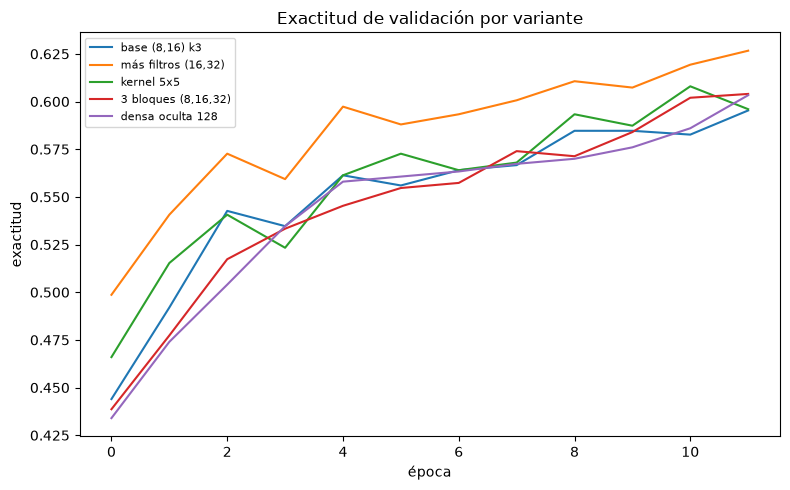

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, (_, history) in trained.items():
    ax.plot(history["val_acc"], label=name)
ax.set_title("Exactitud de validación por variante")
ax.set_xlabel("época")
ax.set_ylabel("exactitud")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Lectura de los experimentos.** Respecto de la base (0.595 de exactitud de validación), duplicar filtros a 16 y 32 ayudó (0.627), con 46.053 parámetros en lugar de 21.877. El kernel 5×5 también mejoró levemente (0.608) pero aumenta los parámetros de las convoluciones. Agregar un tercer bloque mantuvo el resultado (0.604) con *menos* parámetros (16.277), porque los mapas se achican antes de la capa densa. La capa densa oculta de 128 unidades no ayudó (0.603) y multiplicó los parámetros por 24 hasta 526.453, así que se descartó. Por eso gana **más filtros (16,32)**, y es la arquitectura que se analiza a continuación.

### 3.2 Sobreajuste y regularización

La arquitectura ganadora se reentrena dos veces con 20 épocas: una sin regularizar y otra con `dropout=0.3`, `weight_decay=1e-4` y early stopping. El sobreajuste se ve cuando la pérdida de entrenamiento sigue bajando pero la de validación deja de bajar y empieza a subir: la red está memorizando detalles que no se repiten en datos nuevos.

`model.train()` activa dropout (apaga unidades al azar y escala las restantes por $1/(1-p)$); `model.eval()` lo desactiva para usar la red completa al predecir.

In [15]:
best_name = max(results, key=lambda row: row[3])[0]
best_config = variants[best_name]
print("arquitectura elegida por validación:", best_name)

set_seed()
plain, history_plain = train_model(
    CNN(**best_config), *make_loaders()[:2], epochs=20, early_stop=False
)
set_seed()
regularized, history_reg = train_model(
    CNN(**best_config, dropout=0.3), *make_loaders()[:2],
    epochs=20, weight_decay=1e-4, early_stop=True,
)
print("mejor época sin regularizar:", history_plain["best_epoch"])
print("mejor época con regularización:", history_reg["best_epoch"])

arquitectura elegida por validación: más filtros (16,32)


época  1 | train 1.359/0.414 | val 1.163/0.499


época  5 | train 0.992/0.605 | val 0.999/0.597


época 10 | train 0.857/0.670 | val 0.998/0.607


época 15 | train 0.763/0.714 | val 0.982/0.609


época 20 | train 0.623/0.773 | val 0.960/0.628


época  1 | train 1.363/0.415 | val 1.165/0.493


época  5 | train 0.996/0.601 | val 0.996/0.602


época 10 | train 0.874/0.660 | val 0.982/0.608


época 15 | train 0.800/0.697 | val 0.974/0.608


época 20 | train 0.714/0.730 | val 0.934/0.623
mejor época sin regularizar: 16
mejor época con regularización: 20


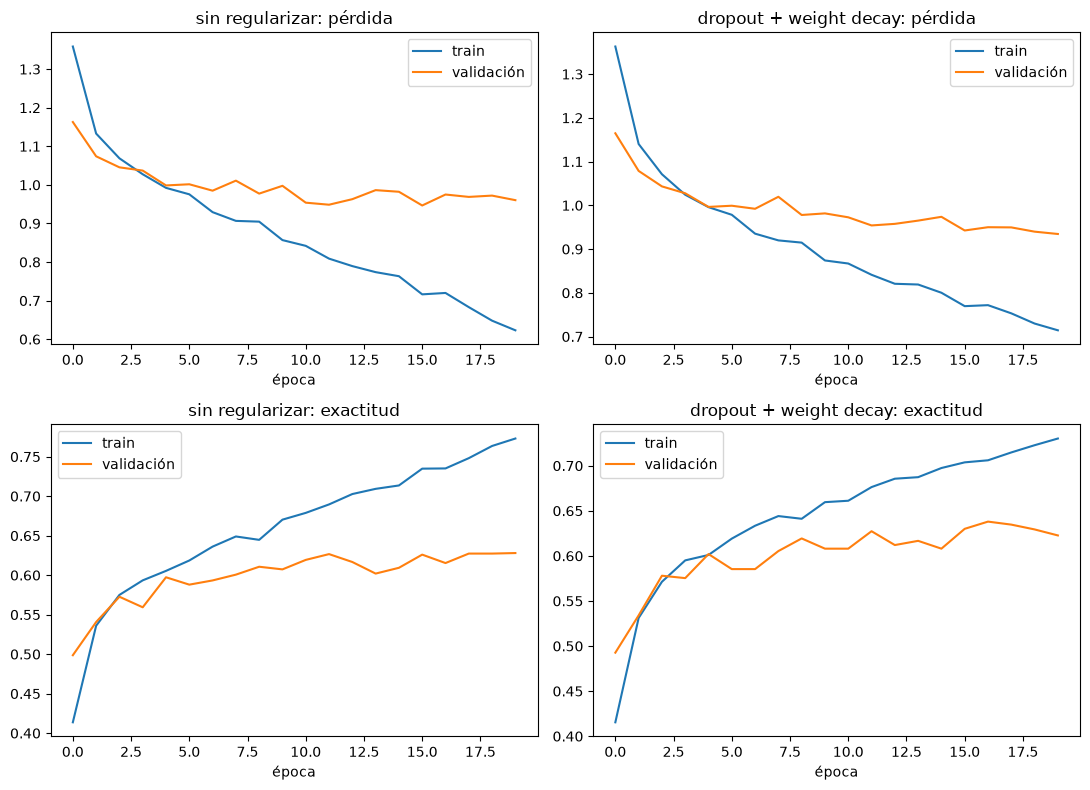

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for column, (history, title) in enumerate([
    (history_plain, "sin regularizar"), (history_reg, "dropout + weight decay")
]):
    axes[0, column].plot(history["train_loss"], label="train")
    axes[0, column].plot(history["val_loss"], label="validación")
    axes[0, column].set_title(f"{title}: pérdida")
    axes[0, column].set_xlabel("época")
    axes[0, column].legend()
    axes[1, column].plot(history["train_acc"], label="train")
    axes[1, column].plot(history["val_acc"], label="validación")
    axes[1, column].set_title(f"{title}: exactitud")
    axes[1, column].set_xlabel("época")
    axes[1, column].legend()
plt.tight_layout()
plt.show()

**Lectura de las curvas.** En la versión sin regularizar la pérdida de entrenamiento baja de 1.359 a 0.623, mientras que la de validación se estabiliza alrededor de 0.96 y la exactitud de entrenamiento (0.773) supera claramente a la de validación (0.628): hay una señal de sobreajuste incipiente. Con dropout, weight decay y early stopping la pérdida de validación baja a 0.934 y la exactitud final de validación queda en 0.623 con una brecha entrenamiento/validación menor (0.730 vs 0.623). Por eso se elige la versión regularizada para el test.

`model.train()` activa el dropout y `model.eval()` lo desactiva: las curvas de validación se miden siempre en modo `eval`, y `torch.no_grad()` evita registrar operaciones innecesarias.

## 4. Análisis

Aquí se usa el conjunto de prueba por primera y única vez: exactitud final del MLP y de la mejor CNN, matriz de confusión, ejemplos mal clasificados con su probabilidad y visualización de los filtros de la primera capa convolucional.

In [17]:
criterion = nn.CrossEntropyLoss()
mlp_test_loss, mlp_test_acc = evaluate(mlp, test_loader, criterion)

if max(history_reg["val_acc"]) >= max(history_plain["val_acc"]):
    final_cnn, final_label = regularized, "CNN regularizada"
else:
    final_cnn, final_label = plain, "CNN sin regularizar"

cnn_test_loss, cnn_test_acc = evaluate(final_cnn, test_loader, criterion)
print(f"MLP               | pérdida {mlp_test_loss:.4f} | exactitud {mlp_test_acc:.4f}")
print(f"{final_label:17s} | pérdida {cnn_test_loss:.4f} | exactitud {cnn_test_acc:.4f}")

MLP               | pérdida 1.2069 | exactitud 0.5000
CNN regularizada  | pérdida 1.0020 | exactitud 0.6153


**Comparación.** El MLP alcanza 0.500 de exactitud en test con 3.179.525 parámetros; la CNN regularizada alcanza 0.615 con 46.053 parámetros, es decir, unas 69 veces menos parámetros y más exactitud. La razón es que la convolución usa conexiones locales (cada salida mira una ventana de 3×3, no los 12288 píxeles) y pesos compartidos (el mismo filtro se aplica en toda la imagen). Así detecta bordes y transiciones de color en cualquier posición sin tener que aprender un peso distinto por lugar, y las capas posteriores combinan esos patrones locales en formas más grandes. El MLP, en cambio, aplana la imagen y trata cada píxel como una feature independiente.

matriz de confusión (filas=real, columnas=predicha):
[[125  38  49  55  33]
 [ 23 165  34  74   4]
 [ 33  37 196  25   9]
 [ 17  50   7 225   1]
 [ 51   6  21  10 212]]


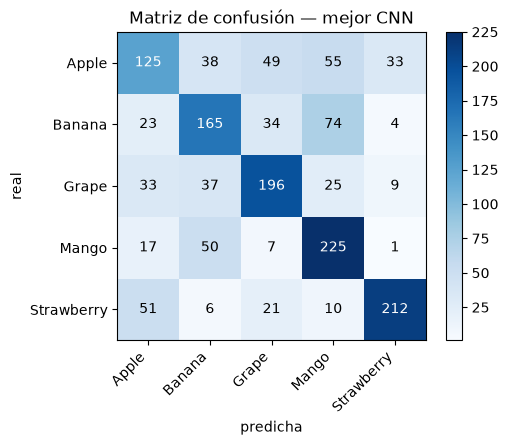

In [18]:
final_cnn.eval()
logits_list, targets_list = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        logits_list.append(final_cnn(xb.to(device)).cpu())
        targets_list.append(yb)
all_logits = torch.cat(logits_list)
all_targets = torch.cat(targets_list)
all_probs = torch.softmax(all_logits, dim=1)
all_preds = all_logits.argmax(dim=1)

cm = confusion_matrix(all_targets.numpy(), all_preds.numpy(), labels=range(5))
print("matriz de confusión (filas=real, columnas=predicha):")
print(cm)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
image = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(5), CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(5), CLASS_NAMES)
ax.set_xlabel("predicha")
ax.set_ylabel("real")
ax.set_title("Matriz de confusión — mejor CNN")
for i in range(5):
    for j in range(5):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

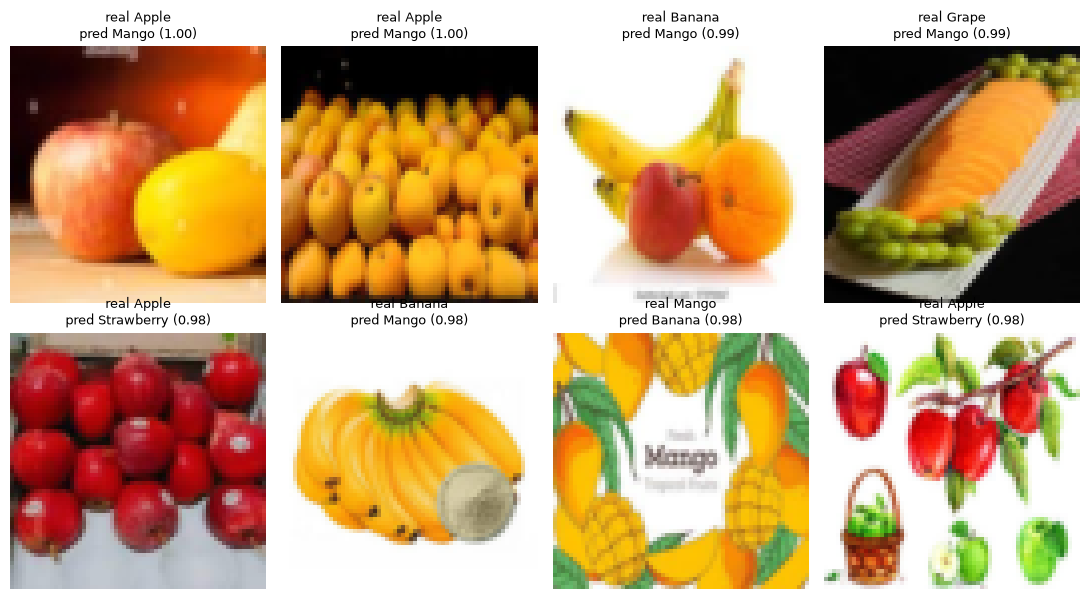

In [19]:
wrong = torch.where(all_preds != all_targets)[0]
confidence = all_probs[wrong].max(dim=1).values
wrong = wrong[torch.argsort(confidence, descending=True)[:8]]

fig, axes = plt.subplots(2, 4, figsize=(11, 6))
for ax, position in zip(axes.flat, wrong.tolist()):
    global_index = int(idx_test[position])
    ax.imshow(X_all[global_index].permute(1, 2, 0).numpy())
    ax.set_title(
        f"real {CLASS_NAMES[int(all_targets[position])]}\n"
        f"pred {CLASS_NAMES[int(all_preds[position])]} "
        f"({all_probs[position, all_preds[position]]:.2f})",
        fontsize=9,
    )
    ax.axis("off")
plt.tight_layout()
plt.show()

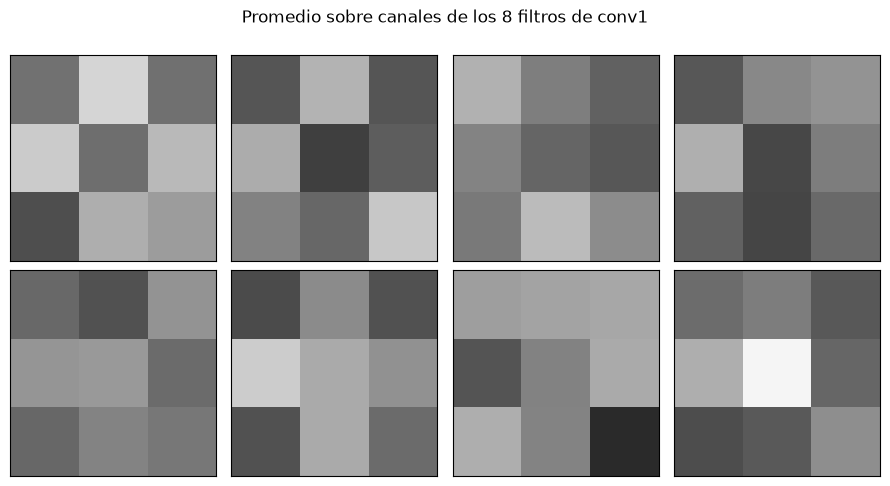

In [20]:
filters = final_cnn.conv_blocks[0][0].weight.detach().cpu().mean(dim=1)
fig, axes = plt.subplots(2, 4, figsize=(9, 5))
for ax, kernel in zip(axes.flat, filters[:8]):
    ax.imshow(kernel.numpy(), cmap="gray", vmin=filters.min().item(), vmax=filters.max().item())
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Promedio sobre canales de los 8 filtros de conv1")
plt.tight_layout()
plt.show()

**Interpretación de los filtros.** Los mapas de la primera convolución muestran principalmente transiciones de intensidad/color: varios filtros responden a bordes verticales u horizontales y otros a manchas localizadas donde la fruta se distingue del fondo. Como se promedia sobre los 3 canales RGB, un peso positivo indica que la red espera más intensidad en esa posición relativa y uno negativo lo contrario; no son detectores perfectamente interpretables, pero muestran que la primera capa aprendió features locales antes que la capa densa.

In [21]:
print(f"{'modelo':18s} {'parámetros':>12s} {'exactitud test':>15s}")
print(f"{'MLP':18s} {sum(p.numel() for p in mlp.parameters()):12d} {mlp_test_acc:15.4f}")
print(f"{final_label:18s} {sum(p.numel() for p in final_cnn.parameters()):12d} {cnn_test_acc:15.4f}")

modelo               parámetros  exactitud test
MLP                     3179525          0.5000
CNN regularizada          46053          0.6153


In [22]:
torch.save(mlp.state_dict(), "mejor_mlp.pt")
torch.save(final_cnn.state_dict(), "mejor_cnn.pt")
print("pesos guardados: mejor_mlp.pt, mejor_cnn.pt")

pesos guardados: mejor_mlp.pt, mejor_cnn.pt


### Explicabilidad — temas de la evaluación

1. **Convolución y pooling a mano.** Están en `conv2d_manual`, `relu_manual` y `maxpool2d_manual` (sección 1.1), con la fórmula $y_{ij}=\sum_{u,v}x_{i+u-1,j+v-1}K_{uv}$ en el markdown anterior. La celda de verificación (1.2) muestra que `nn.Conv2d` coincide. La salida de la convolución es 3×3 porque $5-3+1=3$; el pooling 2×2 stride 1 da 2×2.
2. **Formas y parámetros.** La tabla de la sección 3 y la función `layer_table` muestran la forma de cada capa y `p.numel()`. La primera densa recibe 4096 entradas porque las dos convoluciones conservan 64×64 con padding 1 y los dos pooling reducen a 16×16, con 16 canales. En el MLP, la primera densa recibe $3\cdot64\cdot64=12288$ porque `nn.Flatten` aplana cada imagen.
3. **Por qué la convolucional tiene menos parámetros.** Conexiones locales (cada salida mira una ventana 3×3, no toda la imagen) y pesos compartidos (el mismo filtro se usa en todas las posiciones). Por eso `Conv2d(3,8,3)` tiene 224 parámetros, mientras que una densa equivalente tendría muchos más: en el punto 1, 448 para 3→16 y 44.251.200 para la densa de 3072→14400.
4. **Ciclo de entrenamiento.** Está en `train_model`: `zero_grad()` → `forward` → `CrossEntropyLoss` → `backward()` → `step()`. Sin `zero_grad`, los gradientes se acumulan y el entrenamiento falla silenciosamente. No se aplica softmax antes de la pérdida porque `nn.CrossEntropyLoss` ya aplica log-softmax de forma estable.
5. **Época, mini-batch y paso.** Con 7000 imágenes y batch 128 hay $\lceil7000/128\rceil=55$ pasos por época; en 15 épocas del MLP fueron $15\cdot55=825$ pasos. Un mini-batch son 128 imágenes, un paso es una actualización y una época es una pasada completa.
6. **Experimentos de arquitectura.** La tabla de la sección 3.1 compara base, más filtros, kernel 5×5, tercer bloque y densa oculta. Se cambió una variable a la vez y se eligió por exactitud de validación, dejando el test intacto.
7. **Sobreajuste y train/eval.** Las curvas de la sección 3.2 comparan la arquitectura elegida con y sin regularización. Dropout apaga unidades al azar durante el entrenamiento y `model.eval()` lo desactiva para predecir; `weight_decay` penaliza $\|theta\|^2$; early stopping guarda la época de mínima pérdida de validación.
8. **Matriz de confusión y filtros.** La matriz muestra qué clases se confunden (filas=real, columnas=predicha). Los mapas de la primera convolución muestran patrones locales: manchas claras/oscuras que responden a bordes y transiciones de color; al promediar los 3 canales se resalta la estructura espacial que cada filtro detecta.

**Puntos a ubicar en el código:** `conv2d_manual` (punto 1), `MLP` y `train_model` (punto 2), `CNN` / `layer_table` / `variants` / `train_model` con `dropout` y `weight_decay` (punto 3), y las celdas de `confusion_matrix`, imágenes mal clasificadas, filtros y `torch.save` (punto 4).